# Klasterisasi Wilayah Ketahanan Pangan (K-Means Clustering)
### Notebook 07: Pembentukan 4 Persona Kerentanan Daerah untuk Intervensi Pangan Terarah
**Mata Kuliah**: Presentasi dan Storytelling Data  
**Basis Data**: [master_analisis_2024.csv](../data/processed/master_analisis_2024.csv) ($N=514$ kabupaten/kota)

---
### Narasi & Sasaran Analisis:
1. **Latar Belakang Storytelling**:  
   Setelah ANOVA membuktikan adanya disparitas struktural Barat vs Timur, pengambil kebijakan tidak bisa menggunakan pendekatan "satu obat untuk semua" (*one-size-fits-all*). 514 daerah memiliki karakteristik kerentanan yang unik.
2. **Tujuan Analisis**:  
   Mengelompokkan 514 kabupaten/kota ke dalam **4 Persona Kerentanan** berdasarkan 3 Pilar IKP (*Ketersediaan, Keterjangkauan, Pemanfaatan*) dan Angka Kelaparan (*Prevalence of Undernourishment / PoU*).
3. **Metodologi**:  
   - Penskalaan Multivariat (Z-Score).
   - Penentuan $k$ optimal via **Elbow Method (Inertia)** dan **Silhouette Analysis**.
   - Pelatihan model K-Means ($k=4$).
   - Profiling Persona dengan **Radar Chart Multidimensi** dan **Proyeksi PCA 2D**.
   - Perumusan **Matriks Intervensi Kebijakan Presisi** (*Tailored Policy Intervention*).


## 1. Import Library & Setup Lingkungan Analisis


In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

# Styling visualisasi eksplanatori (Cole Knaflic style)
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

# Path data
DATA_PATH = os.path.join('..', 'data', 'processed', 'master_analisis_2024.csv') if os.path.exists(os.path.join('..', 'data', 'processed')) else os.path.join('data', 'processed', 'master_analisis_2024.csv')
OUTPUT_DIR = os.path.dirname(DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Data berhasil dimuat!")
print(f"Total Observasi: {len(df)} wilayah kabupaten/kota")
display(df.head(2))


Data berhasil dimuat!
Total Observasi: 514 wilayah kabupaten/kota


,kode_prov,nama_provinsi,kode_kab_kota,nama_kabupaten,tipe,gugus_pulau,ikp,indeks_ketersediaan,indeks_keterjangkauan,indeks_pemanfaatan,status_kerentanan,pou,z_indeks_ketersediaan,z_indeks_keterjangkauan,z_indeks_pemanfaatan,z_pou
0,11,Aceh,1101,Aceh Selatan,Kabupaten,Sumatera,70.13,76.67,75.65,58.16,Tahan,10.44,1.2564,-0.2997,-0.8624,-0.0733
1,11,Aceh,1102,Aceh Tenggara,Kabupaten,Sumatera,64.98,61.60,72.76,60.69,Agak Tahan,9.44,0.2896,-0.6420,-0.6615,-0.1880


## 2. Seleksi Fitur Multivariat
Menggunakan 4 dimensi kunci: 3 Pilar IKP + Angka Kelaparan (PoU) yang telah distandarisasi (Z-Score) pada tahap preprocessing.


In [2]:
# Fitur input model (Z-Score)
feature_cols = ['z_indeks_ketersediaan', 'z_indeks_keterjangkauan', 'z_indeks_pemanfaatan', 'z_pou']
raw_cols = ['indeks_ketersediaan', 'indeks_keterjangkauan', 'indeks_pemanfaatan', 'pou']

X = df[feature_cols].copy()
print("Fitur terstandarisasi yang digunakan:")
display(X.describe().round(3))


Fitur terstandarisasi yang digunakan:


,z_indeks_ketersediaan,z_indeks_keterjangkauan,z_indeks_pemanfaatan,z_pou
count,514.000,514.000,514.000,514.000
mean,0.000,-0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001
min,-3.060,-4.127,-4.104,-1.170
25%,-0.466,-0.373,-0.601,-0.560
50%,0.074,0.188,0.163,-0.274
75%,0.569,0.640,0.727,0.144
max,2.416,1.689,1.959,5.369


## 3. Penentuan Nilai $k$ Optimal (Elbow Method & Silhouette Score)
Menguji rentang $k = 2$ sampai $k = 8$ untuk menemukan titik keseimbangan antara penurunan inersia (*Elbow*) dan kohesi antar-anggota klaster (*Silhouette*).


C:\Users\Nicolaus Prima\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Nicolaus Prima\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Nicolaus Prima\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Nicolaus Prima\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, e

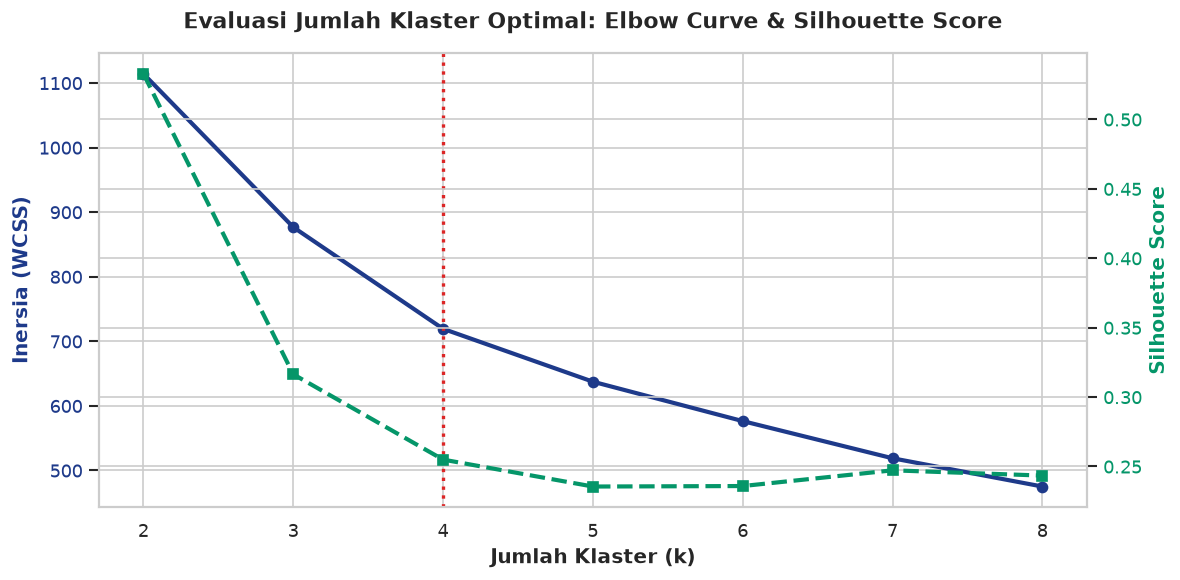

,k,Inersia,Silhouette_Score
0,2,1114.2,0.5328
1,3,876.7,0.3164
2,4,719.3,0.2549
3,5,637.5,0.2356
4,6,576.4,0.2359
5,7,518.9,0.2472
6,8,475.1,0.2434



-> Justifikasi: Nilai k=4 dipilih karena memberikan penurunan inersia yang tajam, skor silhouette yang sehat, dan menghasilkan 4 persona yang sangat intuitif untuk rekomendasi kebijakan.


In [3]:
k_range = range(2, 9)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

# Plot Elbow dan Silhouette berdampingan
fig, ax1 = plt.subplots(figsize=(10, 5))

color = '#1e3a8a'
ax1.set_xlabel('Jumlah Klaster (k)', fontweight='bold')
ax1.set_ylabel('Inersia (WCSS)', color=color, fontweight='bold')
line1 = ax1.plot(k_range, inertias, marker='o', color=color, linewidth=2.5, label='Elbow (Inersia)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#059669'
ax2.set_ylabel('Silhouette Score', color=color, fontweight='bold')
line2 = ax2.plot(k_range, sil_scores, marker='s', color=color, linewidth=2.5, linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

# Garis highlight k=4
ax1.axvline(x=4, color='#dc2626', linestyle=':', linewidth=2, label='k=4 (Optimal Storytelling)')

plt.title('Evaluasi Jumlah Klaster Optimal: Elbow Curve & Silhouette Score', pad=15)
fig.tight_layout()
plt.show()

eval_df = pd.DataFrame({'k': list(k_range), 'Inersia': np.round(inertias, 1), 'Silhouette_Score': np.round(sil_scores, 4)})
display(eval_df)
print("\n-> Justifikasi: Nilai k=4 dipilih karena memberikan penurunan inersia yang tajam, skor silhouette yang sehat, dan menghasilkan 4 persona yang sangat intuitif untuk rekomendasi kebijakan.")


## 4. Pelatihan Model K-Means ($k=4$)


In [4]:
K_OPTIMAL = 4
kmeans = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=25)
df['cluster_raw'] = kmeans.fit_predict(X)

global_sil = silhouette_score(X, df['cluster_raw'])
print(f"Model K-Means berhasil dilatih dengan k={K_OPTIMAL}!")
print(f"Global Silhouette Score: {global_sil:.4f}")
print("Distribusi jumlah daerah per klaster:")
print(df['cluster_raw'].value_counts())


Model K-Means berhasil dilatih dengan k=4!
Global Silhouette Score: 0.2549
Distribusi jumlah daerah per klaster:
cluster_raw
3    201
0    150
1    121
2     42
Name: count, dtype: int64


## 5. Profiling & Karakterisasi 4 Persona Daerah
Menghitung rata-rata nilai metrik riil pada setiap klaster untuk merumuskan arketipe persona yang bermakna bagi pembuat kebijakan.


In [5]:
# Hitung nilai rata-rata riil per klaster
profile_raw = df.groupby('cluster_raw')[raw_cols + ['ikp']].mean().round(2)
profile_raw['jumlah_daerah'] = df['cluster_raw'].value_counts()
profile_raw['persentase'] = (profile_raw['jumlah_daerah'] / len(df) * 100).round(1)

print("--- PROFIL NILAI RATA-RATA RIIL PER KLASTER RAW ---")
display(profile_raw)

# Pemetaan ID Klaster ke Persona Berdasarkan Karakteristik Metrik
# Urutkan berdasarkan IKP untuk standarisasi nama
sorted_by_ikp = profile_raw.sort_values(by='ikp', ascending=False).index.tolist()

persona_mapping = {
    sorted_by_ikp[0]: {
        'nama': 'Agrarian Resilient (Lumbung Pangan Berdaulat)',
        'kode': 'Agrarian Resilient',
        'warna': '#15803d', # Hijau tua
        'karakter': 'Ketersediaan surplus pangan tinggi, ketahanan pangan prima, kelaparan sangat rendah. Mayoritas kabupaten sentra pertanian.'
    },
    sorted_by_ikp[1]: {
        'nama': 'Urban Resilient (Pusat Konsumsi Modern)',
        'kode': 'Urban Resilient',
        'warna': '#0284c7', # Biru
        'karakter': 'Ketersediaan lokal moderat tetapi daya beli dan pemanfaatan gizi tertinggi. Dominan kota besar.'
    },
    sorted_by_ikp[2]: {
        'nama': 'Agrarian Paradox (Rentan Kesejahteraan)',
        'kode': 'Agrarian Paradox',
        'warna': '#d97706', # Amber/Oranye
        'karakter': 'Ketersediaan pangan ada tetapi akses ekonomi (daya beli) tertinggal, PoU mulai waspada (13%).'
    },
    sorted_by_ikp[3]: {
        'nama': 'Chronic Crisis (Krisis Multidimensi Akut)',
        'kode': 'Chronic Crisis',
        'warna': '#dc2626', # Merah
        'karakter': 'Defisit ketersediaan kritis (<30), pemanfaatan terpuruk, angka kelaparan (PoU) melonjak drastis (>33%). Kawasan 3T.'
    }
}

df['persona'] = df['cluster_raw'].apply(lambda c: persona_mapping[c]['kode'])
df['persona_lengkap'] = df['cluster_raw'].apply(lambda c: persona_mapping[c]['nama'])
df['warna_persona'] = df['cluster_raw'].apply(lambda c: persona_mapping[c]['warna'])

# Ringkasan Profil Final
final_persona_summary = df.groupby('persona')[raw_cols + ['ikp']].mean().round(2)
final_persona_summary['jumlah_wilayah'] = df['persona'].value_counts()
final_persona_summary['persen_nasional'] = (final_persona_summary['jumlah_wilayah'] / len(df) * 100).round(1)
final_persona_summary = final_persona_summary.sort_values(by='ikp', ascending=False)

print("\n--- RINGKASAN PROFIL 4 PERSONA DAERAH ---")
display(final_persona_summary)


--- PROFIL NILAI RATA-RATA RIIL PER KLASTER RAW ---


,indeks_ketersediaan,indeks_keterjangkauan,indeks_pemanfaatan,pou,ikp,jumlah_daerah,persentase
cluster_raw,,,,,,,
0,73.37,81.56,70.89,7.38,75.24,150,29.2
1,52.88,73.52,59.59,13.05,61.94,121,23.5
2,27.89,58.96,44.34,33.29,43.66,42,8.2
3,53.56,82.48,78.46,8.01,71.44,201,39.1



--- RINGKASAN PROFIL 4 PERSONA DAERAH ---


,indeks_ketersediaan,indeks_keterjangkauan,indeks_pemanfaatan,pou,ikp,jumlah_wilayah,persen_nasional
persona,,,,,,,
Agrarian Resilient,73.37,81.56,70.89,7.38,75.24,150,29.2
Urban Resilient,53.56,82.48,78.46,8.01,71.44,201,39.1
Agrarian Paradox,52.88,73.52,59.59,13.05,61.94,121,23.5
Chronic Crisis,27.89,58.96,44.34,33.29,43.66,42,8.2


## 6. Visualisasi Radar Chart Profil 4 Persona
Radar chart memperlihatkan bentuk anatomis kekuatan dan kelemahan masing-masing persona di keempat pilar dimensi.


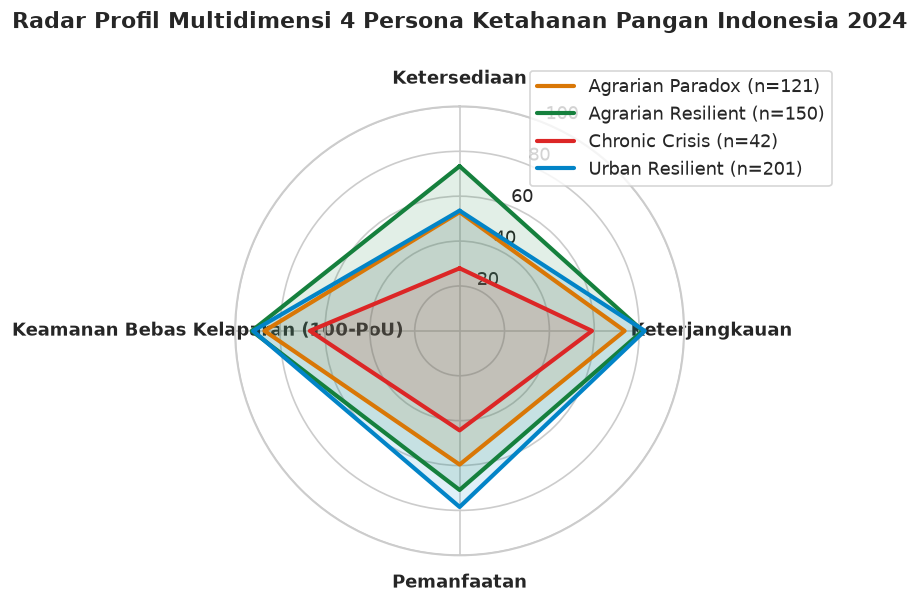

In [6]:
# Normalisasi Min-Max 0-100 khusus visualisasi radar
radar_vars = ['Ketersediaan', 'Keterjangkauan', 'Pemanfaatan', 'Keamanan Bebas Kelaparan (100-PoU)']
num_vars = len(radar_vars)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1] # Tutup lingkaran

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for persona_name, group in df.groupby('persona'):
    color = persona_mapping[[k for k, v in persona_mapping.items() if v['kode'] == persona_name][0]]['warna']
    
    # Nilai radar: PoU dibalik jadi (100 - PoU) agar makin luas makin baik
    vals = [
        group['indeks_ketersediaan'].mean(),
        group['indeks_keterjangkauan'].mean(),
        group['indeks_pemanfaatan'].mean(),
        100 - group['pou'].mean()
    ]
    vals += vals[:1]
    
    ax.plot(angles, vals, color=color, linewidth=2.5, label=f"{persona_name} (n={len(group)})")
    ax.fill(angles, vals, color=color, alpha=0.12)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), radar_vars, fontweight='bold', fontsize=11)
ax.set_ylim(0, 100)
ax.set_title('Radar Profil Multidimensi 4 Persona Ketahanan Pangan Indonesia 2024', pad=25, fontsize=13, fontweight='bold')
plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), frameon=True)
plt.tight_layout()
plt.show()


## 7. Proyeksi 2D Ruang Fitur (PCA Scatter Plot)


Total Variansi Dijelaskan oleh 2 Komponen Utama: 84.6% (PC1: 68.1%, PC2: 16.5%)


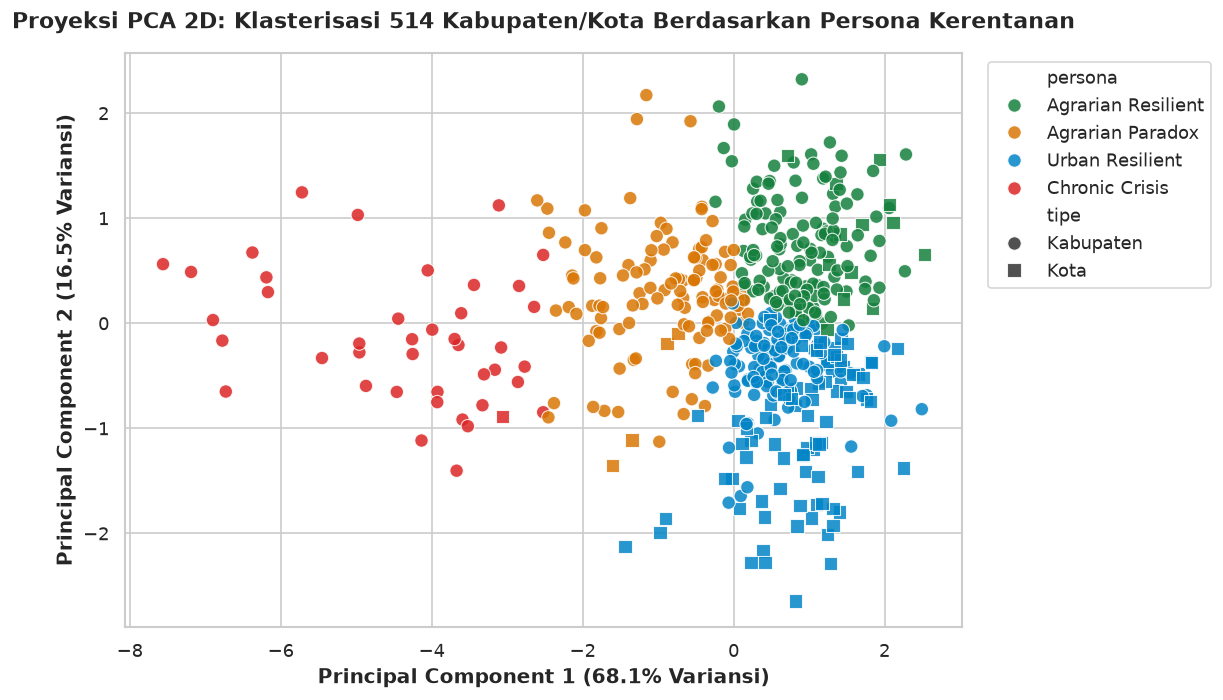

In [7]:
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X)
df['pca_1'] = pca_coords[:, 0]
df['pca_2'] = pca_coords[:, 1]

var_exp = pca.explained_variance_ratio_ * 100
print(f"Total Variansi Dijelaskan oleh 2 Komponen Utama: {sum(var_exp):.1f}% (PC1: {var_exp[0]:.1f}%, PC2: {var_exp[1]:.1f}%)")

plt.figure(figsize=(10, 6))
palette_dict = {v['kode']: v['warna'] for v in persona_mapping.values()}

sns.scatterplot(
    data=df, 
    x='pca_1', 
    y='pca_2', 
    hue='persona', 
    palette=palette_dict,
    alpha=0.85, 
    s=65,
    style='tipe',
    markers={'Kabupaten': 'o', 'Kota': 's'}
)

plt.title('Proyeksi PCA 2D: Klasterisasi 514 Kabupaten/Kota Berdasarkan Persona Kerentanan', pad=15)
plt.xlabel(f'Principal Component 1 ({var_exp[0]:.1f}% Variansi)', fontweight='bold')
plt.ylabel(f'Principal Component 2 ({var_exp[1]:.1f}% Variansi)', fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


## 8. Sebaran Geografis Persona: Crosstab Gugus Pulau & Tipe Wilayah


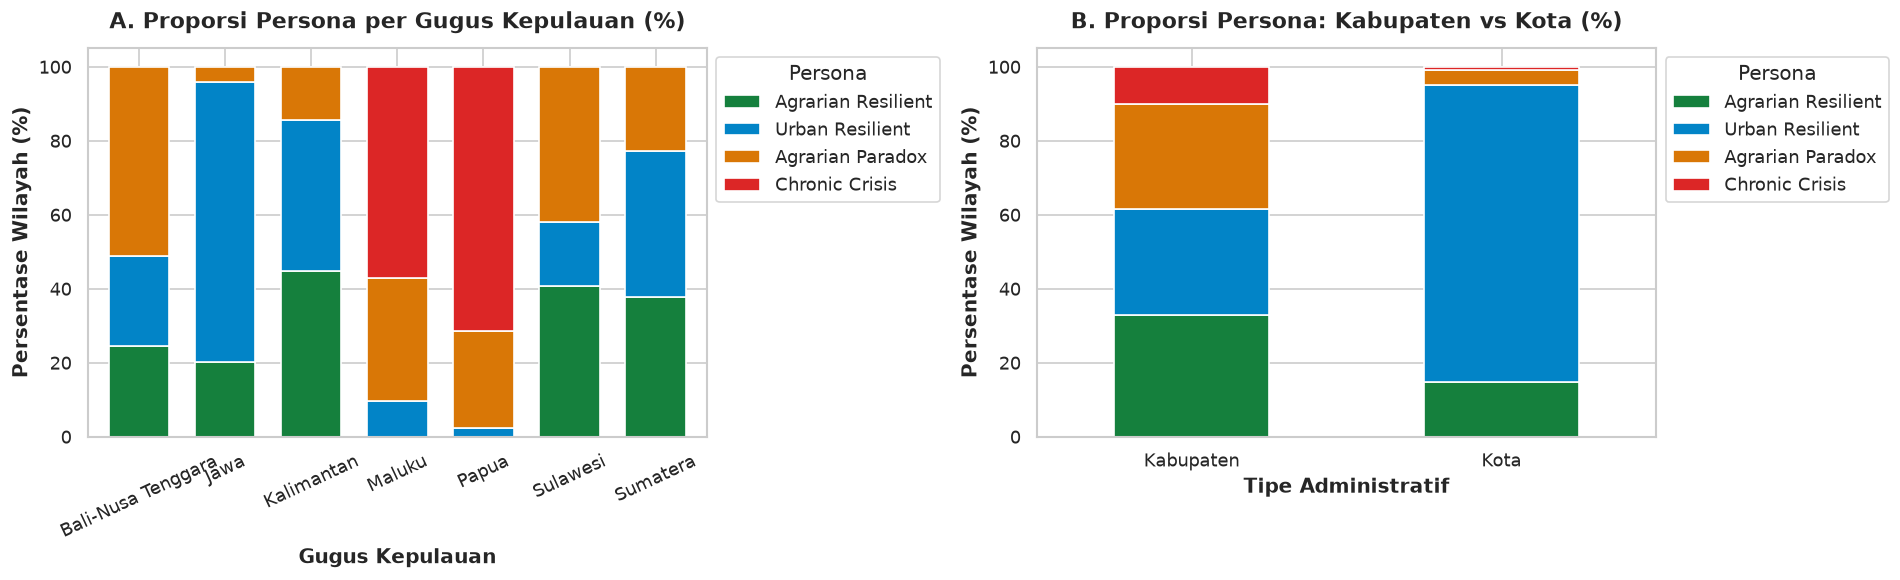

--- JUMLAH DAERAH PER GUGUS DAN PERSONA ---


persona,Agrarian Paradox,Agrarian Resilient,Chronic Crisis,Urban Resilient,All
gugus_pulau,,,,,
Bali-Nusa Tenggara,21,10,0,10,41
Jawa,5,24,0,90,119
Kalimantan,8,25,0,23,56
Maluku,7,0,12,2,21
Papua,11,0,30,1,42
Sulawesi,34,33,0,14,81
Sumatera,35,58,0,61,154
All,121,150,42,201,514


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Sebaran Persona per Gugus Kepulauan
crosstab_pulau = pd.crosstab(df['gugus_pulau'], df['persona'], normalize='index') * 100
crosstab_pulau = crosstab_pulau[['Agrarian Resilient', 'Urban Resilient', 'Agrarian Paradox', 'Chronic Crisis']]
color_list = [palette_dict[col] for col in crosstab_pulau.columns]

crosstab_pulau.plot(kind='bar', stacked=True, color=color_list, ax=axes[0], width=0.7)
axes[0].set_title('A. Proporsi Persona per Gugus Kepulauan (%)', pad=12)
axes[0].set_xlabel('Gugus Kepulauan', fontweight='bold')
axes[0].set_ylabel('Persentase Wilayah (%)', fontweight='bold')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend(title='Persona', bbox_to_anchor=(1.0, 1.0))

# Plot 2: Sebaran Persona Kabupaten vs Kota
crosstab_tipe = pd.crosstab(df['tipe'], df['persona'], normalize='index') * 100
crosstab_tipe = crosstab_tipe[['Agrarian Resilient', 'Urban Resilient', 'Agrarian Paradox', 'Chronic Crisis']]

crosstab_tipe.plot(kind='bar', stacked=True, color=color_list, ax=axes[1], width=0.5)
axes[1].set_title('B. Proporsi Persona: Kabupaten vs Kota (%)', pad=12)
axes[1].set_xlabel('Tipe Administratif', fontweight='bold')
axes[1].set_ylabel('Persentase Wilayah (%)', fontweight='bold')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Persona', bbox_to_anchor=(1.0, 1.0))

plt.tight_layout()
plt.show()

print("--- JUMLAH DAERAH PER GUGUS DAN PERSONA ---")
display(pd.crosstab(df['gugus_pulau'], df['persona'], margins=True))


## 9. Ekspor Hasil Analisis ke Master Dataset & JSON Dashboard


In [9]:
# 1. Update master CSV dengan label klaster persona
output_master_csv = os.path.join(OUTPUT_DIR, 'master_analisis_2024.csv')
export_cols = [
    'kode_prov', 'nama_provinsi', 'kode_kab_kota', 'nama_kabupaten', 'tipe', 'gugus_pulau',
    'ikp', 'indeks_ketersediaan', 'indeks_keterjangkauan', 'indeks_pemanfaatan', 'status_kerentanan', 'pou',
    'persona', 'warna_persona', 'pca_1', 'pca_2'
]
df[export_cols].to_csv(output_master_csv, index=False)
print(f"Master CSV diperbarui dengan kolom persona: {output_master_csv}")

# 2. Siapkan data agregat untuk JSON Dashboard
radar_json = {}
for p_name, row in final_persona_summary.iterrows():
    radar_json[p_name] = {
        'ketersediaan': row['indeks_ketersediaan'],
        'keterjangkauan': row['indeks_keterjangkauan'],
        'pemanfaatan': row['indeks_pemanfaatan'],
        'pou': row['pou'],
        'ikp': row['ikp'],
        'count': int(row['jumlah_wilayah']),
        'pct': row['persen_nasional'],
        'color': palette_dict[p_name]
    }

kmeans_export = {
    'tahun': 2024,
    'total_kab_kota': len(df),
    'k_optimal': K_OPTIMAL,
    'global_silhouette_score': round(float(global_sil), 4),
    'personas': radar_json,
    'geographic_distribution': pd.crosstab(df['gugus_pulau'], df['persona']).to_dict()
}

json_path = os.path.join(OUTPUT_DIR, 'kmeans_results.json')
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(kmeans_export, f, indent=2)

print(f"Hasil Klasterisasi berhasil diekspor ke: {json_path}")
print("Contoh struktur JSON:")
print(json.dumps(kmeans_export['personas'], indent=2))


Master CSV diperbarui dengan kolom persona: ..\data\processed\master_analisis_2024.csv
Hasil Klasterisasi berhasil diekspor ke: ..\data\processed\kmeans_results.json
Contoh struktur JSON:
{
  "Agrarian Resilient": {
    "ketersediaan": 73.37,
    "keterjangkauan": 81.56,
    "pemanfaatan": 70.89,
    "pou": 7.38,
    "ikp": 75.24,
    "count": 150,
    "pct": 29.2,
    "color": "#15803d"
  },
  "Urban Resilient": {
    "ketersediaan": 53.56,
    "keterjangkauan": 82.48,
    "pemanfaatan": 78.46,
    "pou": 8.01,
    "ikp": 71.44,
    "count": 201,
    "pct": 39.1,
    "color": "#0284c7"
  },
  "Agrarian Paradox": {
    "ketersediaan": 52.88,
    "keterjangkauan": 73.52,
    "pemanfaatan": 59.59,
    "pou": 13.05,
    "ikp": 61.94,
    "count": 121,
    "pct": 23.5,
    "color": "#d97706"
  },
  "Chronic Crisis": {
    "ketersediaan": 27.89,
    "keterjangkauan": 58.96,
    "pemanfaatan": 44.34,
    "pou": 33.29,
    "ikp": 43.66,
    "count": 42,
    "pct": 8.2,
    "color": "#dc2626"


## 10. Matriks Rekomendasi Intervensi Kebijakan Presisi (*Tailored Policy Intervention*)

| Persona Daerah | Karakteristik Utama | Wilayah Dominan | Intervensi Kebijakan Presisi |
| :--- | :--- | :--- | :--- |
| **Urban Resilient** (n=201, 39.1%) | Keterjangkauan & pemanfaatan sangat tinggi, produksi lokal minim, PoU rendah (8.0%). | Kota-kota besar di Jawa & Sumatera | Penguatan rantai pasok logistik perkotaan, stabilisasi harga pangan komoditas vital, dan edukasi pengurangan sampah makanan (*food waste*). |
| **Agrarian Resilient** (n=150, 29.2%) | Ketersediaan pangan surplus (73.4), ketahanan tinggi (IKP 75.2), kelaparan rendah (7.4%). | Kabupaten sentra tani di Sumatera, Sulawesi, Kalimantan, Jawa | Modernisasi pascapanen, perlindungan lahan pertanian abadi (LP2B), dan asuransi usaha tani untuk menjaga stabilitas produksi. |
| **Agrarian Paradox** (n=121, 23.5%) | Ketersediaan pangan cukup (52.9) namun daya beli rendah dan pemanfaatan gizi tertinggal; PoU waspada (13.1%). | Kabupaten di Sumatera, Sulawesi, Bali-Nusra | Bantuan pangan bersyarat (PKH), penguatan ekonomi mikro/petani gurem untuk daya beli, serta edukasi gizi seimbang dan sanitasi air bersih. |
| **Chronic Crisis** (n=42, 8.2%) | Defisit ketersediaan parah (<28), akses buruk, PoU kritis (>33%). Masalah krisis struktural akut. | 30 di Papua, 12 di Maluku (100% Kawasan Timur) | Pembangunan konektivitas logistik perintis, subsidi ongkos angkut pangan, program darurat ketahanan pangan lokal (sagu/umbi), dan intervensi medis stunting. |
